# Notebook 02 — Material Clustering using K-Means

## Objective

This notebook explores whether construction product variants can be grouped according to similar thermal characteristics.

We will use **K-Means**, an unsupervised machine-learning method. It groups records based on how close their selected property values are to one another.

For this first experiment, we will use:
- `thermal_conductivity_W_mK` — how easily heat passes through a material.
- `thickness_mm` — the thickness of the product variant.

We will not use material-family labels to create the clusters. We will inspect those labels afterwards to understand what the clusters contain.

**Important:** A cluster is a group of similar records. It is not a product approval, compliance result, or material classification decision.

## 1. Environment and project path

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)

DATASET_RELATIVE = Path(
    "04_Product_Dataset",
    "10_Master_Database",
    "SpecSynth_Master_Database_v1.0",
    "source_data",
    "v1.5.0"
)

def find_project_root(start):
    start = start.resolve()
    for candidate in [start, *start.parents]:
        dataset_file = (
            candidate / DATASET_RELATIVE / "ml" /
            "SpecSynth_ML_variants_v1.5.0.csv"
        )
        if dataset_file.exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the SpecSynth project root. "
        "Open this notebook from inside the SpecSynth_AI project."
    )

PROJECT_ROOT = find_project_root(Path.cwd())
ML_ROOT = PROJECT_ROOT / "06_AI_Performance_Engine" / "02_ML_Engine"
DATA_DIR = PROJECT_ROOT / DATASET_RELATIVE / "ml"

MODEL_DIR = ML_ROOT / "03_Models" / "material_clustering"
REPORT_DIR = ML_ROOT / "04_Evaluation" / "reports"
FIGURE_DIR = ML_ROOT / "04_Evaluation" / "figures"

for folder in [MODEL_DIR, REPORT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "SpecSynth_ML_variants_v1.5.0.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset:", CSV_PATH)
print("Model output:", MODEL_DIR)
print("Report output:", REPORT_DIR)

Project root: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI
Dataset: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\04_Product_Dataset\10_Master_Database\SpecSynth_Master_Database_v1.0\source_data\v1.5.0\ml\SpecSynth_ML_variants_v1.5.0.csv
Model output: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\material_clustering
Report output: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports


### Outcome and conclusion

The notebook successfully located the SpecSynth AI project and the v1.5.0 product dataset. It also created the folders where the clustering model and its reports will be saved.

No source data has been changed.

## 2. Load and inspect the product dataset

In [2]:
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
display(df.head(5))

required_columns = [
    "record_id",
    "variant_id",
    "product_id",
    "material_family",
    "recommended_split",
    "thickness_mm",
    "thermal_conductivity_W_mK",
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise KeyError(f"Required columns are missing: {missing_columns}")

print("\\nMaterial families:", df["material_family"].nunique())
print("Split groups:", df["recommended_split"].value_counts(dropna=False).to_dict())

Dataset shape: (1941, 47)


,record_id,product_id,variant_id,material_category_group,material_family,category,manufacturer,market,record_origin,dataset_version_added,...,qa_flag_count,qa_flags,source_ids,split_group_id,target_thermal_conductivity_W_mK,target_density_kg_m3,target_specific_heat_J_kgK,target_gwp_a1_a3_kgco2e_m2,target_price_per_m2,recommended_split
0,ML_UNILIN_UTHERM_WALL_A_40MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_40MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
1,ML_UNILIN_UTHERM_WALL_A_50MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_50MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
2,ML_UNILIN_UTHERM_WALL_A_60MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_60MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
3,ML_UNILIN_UTHERM_WALL_A_70MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_70MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train
4,ML_UNILIN_UTHERM_WALL_A_80MM,UNILIN_UTHERM_WALL_A,UNILIN_UTHERM_WALL_A_80MM,A_thermal_insulation,PIR,PIR insulation board,UNILIN Insulation,NaN,legacy_v1.2.0,1.2.0,...,0,NaN,SRC_UNILIN_DOP;SRC_UNILIN_TDS,UNILIN_UTHERM_WALL_A,0.022,32.0,NaN,NaN,NaN,train


\nMaterial families: 32
Split groups: {'train': 1621, 'validation': 186, 'test': 134}


### Outcome and conclusion

The dataset contains **1,941 records and 47 columns**, covering **32 material families**. The original dataset split contains 1,621 training, 186 validation and 134 test records.

We will use material-family labels only after clustering, to understand which products appear in each group. This is important because K-Means should discover groups from the selected numerical properties rather than simply repeat the existing material-family labels.

## 3. Prepare records for clustering

In [3]:
feature_columns = ["thermal_conductivity_W_mK", "thickness_mm"]
metadata_columns = [
    "record_id", "variant_id", "product_id",
    "material_family", "recommended_split"
]

work = df[metadata_columns + feature_columns].copy()

for col in feature_columns:
    work[col] = pd.to_numeric(work[col], errors="coerce")

valid_mask = (
    work[feature_columns].notna().all(axis=1)
    & (work[feature_columns] > 0).all(axis=1)
)

analysis = work.loc[valid_mask].copy()

print("Original records:", len(df))
print("Eligible records:", len(analysis))
print("Excluded records:", len(df) - len(analysis))
print("\\nEligible records by split:")
display(analysis["recommended_split"].value_counts(dropna=False).rename("records").to_frame())
print("\\nFeature summary:")
display(analysis[feature_columns].describe().T)

Original records: 1941
Eligible records: 1777
Excluded records: 164
\nEligible records by split:


,records
recommended_split,
train,1489
validation,174
test,114


\nFeature summary:


,count,mean,std,min,25%,50%,75%,max
thermal_conductivity_W_mK,1777.0,0.039532,0.033039,0.019,0.031,0.034,0.037,0.35
thickness_mm,1777.0,137.193022,85.469546,6.000,70.000,120.000,190.000,528.00


### Outcome and conclusion

Out of 1,941 records, **1,777 records** had valid, positive values for both selected properties and could be included. **164 records** were excluded because thickness or thermal conductivity was missing or invalid.

The eligible records are split into:
- Training: **1,489**
- Validation: **174**
- Testing: **114**

The two features have very different numerical scales: thermal conductivity ranges from **0.019 to 0.350 W/mK**, while thickness ranges from **6 to 528 mm**. We therefore scale the features before clustering so that thickness does not dominate simply because its numerical values are larger.

## 4. Explore the selected properties

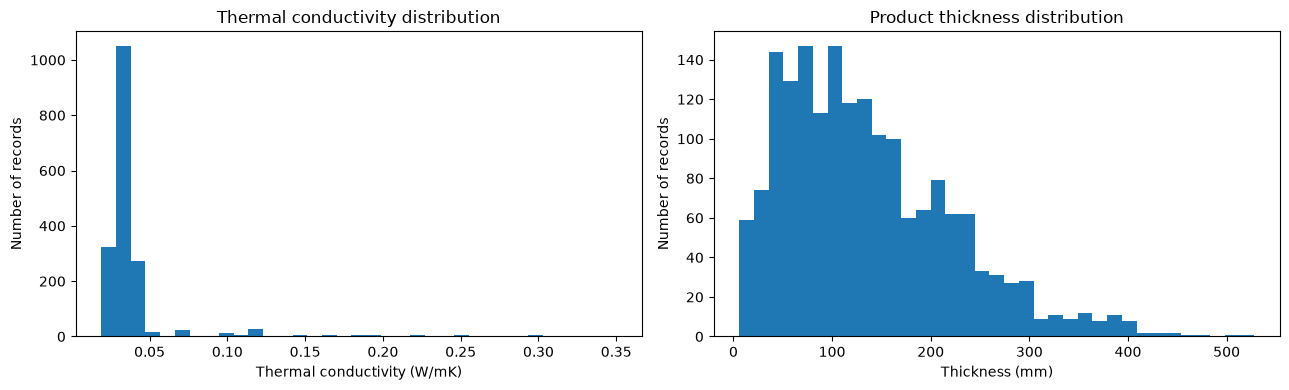

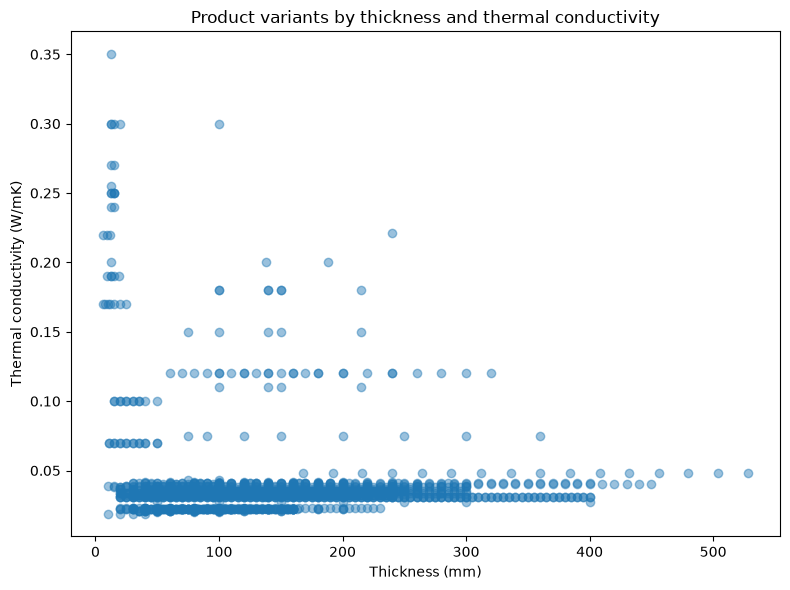

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(analysis["thermal_conductivity_W_mK"], bins=35)
axes[0].set_title("Thermal conductivity distribution")
axes[0].set_xlabel("Thermal conductivity (W/mK)")
axes[0].set_ylabel("Number of records")

axes[1].hist(analysis["thickness_mm"], bins=35)
axes[1].set_title("Product thickness distribution")
axes[1].set_xlabel("Thickness (mm)")
axes[1].set_ylabel("Number of records")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(
    analysis["thickness_mm"],
    analysis["thermal_conductivity_W_mK"],
    alpha=0.45
)
plt.xlabel("Thickness (mm)")
plt.ylabel("Thermal conductivity (W/mK)")
plt.title("Product variants by thickness and thermal conductivity")
plt.tight_layout()
plt.show()

### Outcome and conclusion

The distributions show that the dataset contains a wide range of thicknesses and thermal conductivity values. The scatter plot is particularly useful because it shows the two properties together.

The eligible records have an average thickness of about **137.2 mm** and an average thermal conductivity of about **0.0395 W/mK**. The maximum conductivity, **0.350 W/mK**, is much higher than the typical values in the dataset. This reflects the fact that the dataset contains different types of construction products, not only insulation.

This wide variation gives K-Means a basis for finding groups, but it also means that the resulting groups may separate broad product-performance patterns rather than individual material families.

## 5. Scale the features using the training records

In [5]:
train_mask = analysis["recommended_split"].astype(str).str.lower().eq("train")
if train_mask.sum() < 10:
    raise ValueError("Too few training records. Check recommended_split values.")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(analysis.loc[train_mask, feature_columns])
X_all_scaled = scaler.transform(analysis[feature_columns])

print("Training records used to fit scaler:", int(train_mask.sum()))
print("All eligible records transformed:", len(analysis))
print("Scaled training array shape:", X_train_scaled.shape)

Training records used to fit scaler: 1489
All eligible records transformed: 1777
Scaled training array shape: (1489, 2)


### Outcome and conclusion

The scaler was fitted using the **1,489 training records** and then applied to all **1,777 eligible records**. The scaled training data contains 1,489 rows and two features.

This step puts thickness and thermal conductivity onto comparable scales. Without scaling, thickness could have a much stronger influence on the distance calculations simply because its numbers are larger.

The validation and test records were transformed using the training-fitted scaler; they were not used to fit it.

## 6. Choose a suitable number of clusters

c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_

,k,inertia,silhouette_score
0,2,1707.438155,0.793346
1,3,731.591268,0.561790
2,4,500.428975,0.487299
3,5,401.443672,0.444936
4,6,316.005038,0.471704
5,7,231.638372,0.476744
6,8,189.741860,0.436609


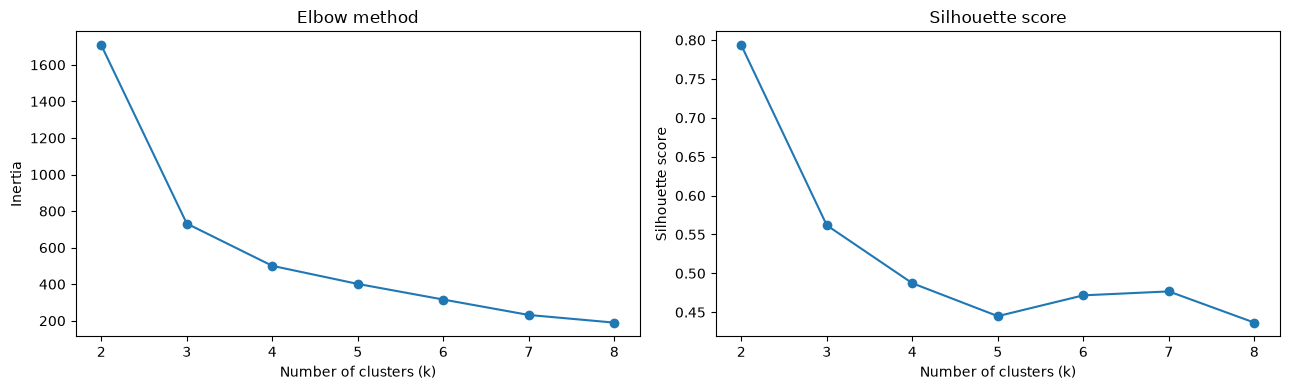

Best k by silhouette score: 2


In [6]:
candidate_k = range(2, 9)
inertias = []
silhouette_scores = []

for k in candidate_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels = model.fit_predict(X_train_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_train_scaled, labels)
    )

k_results = pd.DataFrame({
    "k": list(candidate_k),
    "inertia": inertias,
    "silhouette_score": silhouette_scores
})
display(k_results)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(k_results["k"], k_results["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_results["k"], k_results["silhouette_score"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

best_k = int(k_results.loc[k_results["silhouette_score"].idxmax(), "k"])
print("Best k by silhouette score:", best_k)

### Outcome and conclusion

We tested cluster counts from **2 to 8** using the training records. The silhouette scores were:

| Number of clusters (K) | Silhouette score |
|---:|---:|
| 2 | **0.793** |
| 3 | 0.562 |
| 4 | 0.487 |
| 5 | 0.445 |
| 6 | 0.472 |
| 7 | 0.477 |
| 8 | 0.437 |

The highest score was produced by **K = 2**. This means that, among the tested choices, two groups were the most clearly separated according to this score.

The score does not prove that two clusters are the only useful way to organise construction products. It tells us that two groups provide the clearest separation for these two selected features in this experiment. We must still inspect what the groups contain and whether they are useful for SpecSynth AI.

## 7. Train the final K-Means model and assign clusters

In [7]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)
kmeans.fit(X_train_scaled)

cluster_labels = kmeans.predict(X_all_scaled)

clustered = analysis.copy()
clustered["cluster"] = cluster_labels

print("Cluster assignment completed.")
print("\\nRecords per cluster:")
display(
    clustered["cluster"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

Cluster assignment completed.
\nRecords per cluster:


c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


,records
cluster,
0,1723
1,54


### Outcome and conclusion

The final K-Means model was trained with **2 clusters** using the training data. It then assigned all 1,777 eligible records to one of those clusters:

- **Cluster 0: 1,723 records**
- **Cluster 1: 54 records**

The clusters are very different in size. This indicates that the model has identified one large group and one much smaller group. The next sections help us understand what distinguishes them.

Cluster numbers are only labels. Cluster 0 is not better or more reliable than Cluster 1.

## 8. Visualise the material clusters

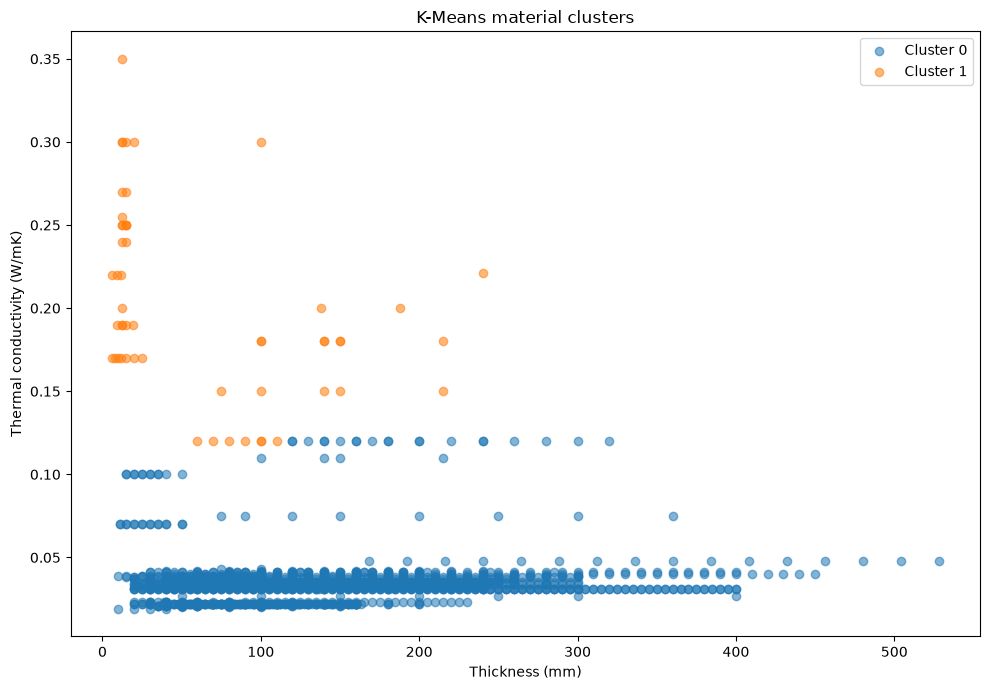

In [8]:
plt.figure(figsize=(10, 7))

for cluster_id in sorted(clustered["cluster"].unique()):
    subset = clustered[clustered["cluster"] == cluster_id]
    plt.scatter(
        subset["thickness_mm"],
        subset["thermal_conductivity_W_mK"],
        alpha=0.55,
        label=f"Cluster {cluster_id}"
    )

plt.xlabel("Thickness (mm)")
plt.ylabel("Thermal conductivity (W/mK)")
plt.title("K-Means material clusters")
plt.legend()
plt.tight_layout()
plt.show()

### Outcome and conclusion

The scatter plot shows that the two clusters separate mainly by thermal conductivity and, to a lesser extent, thickness. Most records fall into Cluster 0, while a smaller group with substantially higher conductivity values is assigned to Cluster 1.

This visual separation is consistent with the cluster profile in the next section. It suggests that the model has mainly separated the large group of lower-conductivity products from a smaller group of higher-conductivity products.

This is a grouping based on only two properties. It should not be treated as an official material classification or a statement that products in the same cluster can replace one another.

## 9. Understand the properties of each cluster

In [9]:
cluster_profile = (
    clustered.groupby("cluster")
    .agg(
        records=("record_id", "count"),
        average_thickness_mm=("thickness_mm", "mean"),
        median_thickness_mm=("thickness_mm", "median"),
        average_thermal_conductivity_W_mK=("thermal_conductivity_W_mK", "mean"),
        median_thermal_conductivity_W_mK=("thermal_conductivity_W_mK", "median"),
    )
    .round(3)
)

display(cluster_profile)

,records,average_thickness_mm,median_thickness_mm,average_thermal_conductivity_W_mK,median_thermal_conductivity_W_mK
cluster,,,,,
0,1723,139.540,123.0,0.034,0.033
1,54,62.315,17.0,0.201,0.190


### Outcome and conclusion

The cluster profile shows a clear difference between the two groups:

| Measure | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Number of records | **1,723** | **54** |
| Average thickness | 139.54 mm | 62.32 mm |
| Median thickness | 123 mm | 17 mm |
| Average thermal conductivity | **0.034 W/mK** | **0.201 W/mK** |
| Median thermal conductivity | 0.033 W/mK | 0.190 W/mK |

Cluster 0 contains the large group of products with lower thermal conductivity. Cluster 1 contains a much smaller group with considerably higher thermal conductivity and generally lower thickness.

In simple terms, the model has mainly separated products with insulation-like thermal properties from a smaller group of products with higher conductivity. This is a useful pattern to discover, but it does not mean that every product in Cluster 0 is insulation or that every product in Cluster 1 belongs to one specific material type.

## 10. Inspect material-family composition

In [10]:
family_counts = pd.crosstab(
    clustered["cluster"],
    clustered["material_family"]
)
display(family_counts)

family_share = family_counts.div(family_counts.sum(axis=1), axis=0) * 100
display(family_share.round(1))

top_families = (
    clustered.groupby(["cluster", "material_family"])
    .size()
    .rename("records")
    .reset_index()
    .sort_values(["cluster", "records"], ascending=[True, False])
    .groupby("cluster")
    .head(5)
)
display(top_families)

material_family,AAC,CLT,EPS,Gypsum board,PF,PIR,PIR_sandwich_panel,PUR,PUR_sandwich_panel,XPS,...,glass_wool,glass_wool_loosefill,gypsum_board,gypsum_specialist_board,hemp_lime,polyester_wool,recycled_cotton,stone_wool,wood_fibre,wood_wool
cluster,,,,,,,,,,,,,,,,,,,,,
0,4,20,366,0,24,187,63,25,14,167,...,415,12,0,0,8,28,16,151,34,28
1,12,7,0,1,0,0,0,0,0,0,...,0,0,13,6,0,0,0,0,0,0


material_family,AAC,CLT,EPS,Gypsum board,PF,PIR,PIR_sandwich_panel,PUR,PUR_sandwich_panel,XPS,...,glass_wool,glass_wool_loosefill,gypsum_board,gypsum_specialist_board,hemp_lime,polyester_wool,recycled_cotton,stone_wool,wood_fibre,wood_wool
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.2,1.2,21.2,0.0,1.4,10.9,3.7,1.5,0.8,9.7,...,24.1,0.7,0.0,0.0,0.5,1.6,0.9,8.8,2.0,1.6
1,22.2,13.0,0.0,1.9,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,24.1,11.1,0.0,0.0,0.0,0.0,0.0,0.0


,cluster,material_family,records
12,0,glass_wool,415
2,0,EPS,366
4,0,PIR,187
8,0,XPS,167
17,0,stone_wool,151
26,1,gypsum_board,13
20,1,AAC,12
23,1,calcium_silicate_board,10
21,1,CLT,7
27,1,gypsum_specialist_board,6


### Outcome and conclusion

The family breakdown helps explain what the two clusters contain.

**Cluster 0** is dominated by common insulation families:
- Glass wool: **415 records**
- EPS: **366 records**
- PIR: **187 records**
- XPS: **167 records**
- Stone wool: **151 records**

**Cluster 1** contains more of the higher-conductivity or non-insulation product families:
- Gypsum board: **13 records**
- AAC: **12 records**
- Calcium silicate board: **10 records**
- CLT: **7 records**
- Gypsum specialist board: **6 records**

This supports the interpretation that the two clusters mainly separate lower-conductivity insulation-like products from a smaller group of products with higher conductivity.

However, Cluster 0 and Cluster 1 are not equivalent to the dataset's official material categories. For example, Cluster 0 also contains some CLT and AAC records, while Cluster 1 includes some AAC and CLT. The model is grouping numerical properties, not material names.

The result is useful for exploring the catalogue, but product selection still needs other properties such as fire performance, moisture behaviour, strength, intended application and manufacturer evidence.

## 11. Save model, scaler and clustering results

In [11]:
import joblib

model_path = MODEL_DIR / "kmeans_material_clustering_v1.joblib"
scaler_path = MODEL_DIR / "kmeans_material_scaler_v1.joblib"
results_path = REPORT_DIR / "material_clustering_results_v1.csv"
profile_path = REPORT_DIR / "material_clustering_profile_v1.csv"
summary_path = REPORT_DIR / "material_clustering_summary_v1.json"

joblib.dump(kmeans, model_path)
joblib.dump(scaler, scaler_path)

clustered.to_csv(results_path, index=False)
cluster_profile.to_csv(profile_path)

summary = {
    "experiment": "KMeans material clustering",
    "dataset_version": "v1.5.0",
    "original_records": int(len(df)),
    "eligible_records": int(len(analysis)),
    "excluded_records": int(len(df) - len(analysis)),
    "features": feature_columns,
    "selected_k": int(best_k),
    "selection_method": "highest silhouette score among k=2..8 on training records",
    "training_records": int(train_mask.sum()),
    "cluster_counts": {
        str(k): int(v)
        for k, v in clustered["cluster"].value_counts().sort_index().items()
    },
    "warning": "Clusters describe similarity in selected features; they are not compliance or product approval labels."
}

summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved model:", model_path)
print("Saved scaler:", scaler_path)
print("Saved results:", results_path)
print("Saved profile:", profile_path)
print("Saved summary:", summary_path)

Saved model: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\material_clustering\kmeans_material_clustering_v1.joblib
Saved scaler: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\material_clustering\kmeans_material_scaler_v1.joblib
Saved results: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_clustering_results_v1.csv
Saved profile: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_clustering_profile_v1.csv
Saved summary: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_clustering_su

### Outcome and conclusion

The notebook successfully saved:
- The trained K-Means model.
- The fitted feature scaler.
- The record-level cluster assignments.
- The cluster profile table.
- The experiment summary in JSON format.

These files can be reused in later analysis. The original product dataset remains unchanged.

A Windows MKL warning appeared during K-Means fitting. It did not stop execution: the model completed, cluster assignments were produced and all output files were saved. It is a performance-related warning rather than a model-result error. If it becomes disruptive in future runs, we can limit the number of OpenMP threads as suggested by the warning.

# Final conclusion — Material Clustering using K-Means

## What did we do?

We used K-Means to explore whether construction product variants can be grouped according to two properties:

- Thermal conductivity — how easily heat passes through a material.
- Thickness — how thick the product variant is.

The model learned the groups using training records. Material-family labels were inspected afterwards to help us understand the groups; they were not used to create them.

## What data was used?

The original dataset contained **1,941 records**. Of these, **1,777 records** had valid values for both selected properties and were included. The remaining **164 records** were excluded from this experiment because one or both selected values were missing or invalid.

The scaler and clustering model were fitted using the training records only. The existing dataset split was preserved.

## What did the model find?

We tested between 2 and 8 clusters. The highest silhouette score was **0.793 with K = 2**, so we selected two clusters for this experiment.

The model assigned the records as follows:

- **Cluster 0: 1,723 records**
- **Cluster 1: 54 records**

The two groups are very different in size. Their property profiles show why:

| Measure | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Records | 1,723 | 54 |
| Average thickness | 139.54 mm | 62.32 mm |
| Average thermal conductivity | 0.034 W/mK | 0.201 W/mK |

Cluster 0 contains products with lower thermal conductivity on average. It is dominated by insulation families such as glass wool, EPS, PIR, XPS and stone wool.

Cluster 1 contains products with much higher thermal conductivity on average. It includes more records from families such as gypsum board, AAC, calcium silicate board, CLT and gypsum specialist board.

## What does this mean?

The model has mainly separated the large group of lower-conductivity, insulation-like products from a much smaller group of products with higher conductivity.

This is a useful discovery for understanding the product catalogue. It shows that clustering can reveal patterns that are not explicitly provided as labels in the dataset.

However, the clusters are not official material categories. Some material families appear in both groups, and products in the same cluster are not automatically interchangeable.

## Important limitations

- Only thickness and thermal conductivity were used. The model did not consider fire performance, moisture behaviour, density, strength, environmental impact, price or intended application.
- The dataset contains many more insulation records than other material types. This affects the groups the model can discover.
- K = 2 was selected because it had the highest silhouette score among the tested values from 2 to 8. Other choices or additional features may reveal different groupings.
- Clustering measures similarity in the selected numerical features. It does not verify product quality, compliance or suitability.

## What does this mean for SpecSynth AI?

Clustering could help organise and explore the product catalogue. It may help users find products with similar thermal characteristics and reveal groups that deserve further investigation.

It should be treated as an exploratory support feature—not as a product approval, compliance check or automatic replacement recommendation.

## Final takeaway

**The K-Means experiment successfully grouped 1,777 eligible product records into two clusters. The larger cluster is dominated by lower-conductivity insulation products, while the smaller cluster contains products with higher conductivity on average.**

The result demonstrates the value of clustering for discovering patterns in the SpecSynth dataset. Before using these groups in the product workflow, we should consider additional properties and verify that the groupings are useful for real architectural and engineering decisions.

The model, scaler, cluster assignments and summary reports were saved successfully for future use.

# 12. Compare multiple clustering algorithms

The first experiment used K-Means. We will now compare it with two other clustering approaches:

- **K-Means:** groups records around cluster centres.
- **Gaussian Mixture Model (GMM):** models groups as overlapping statistical distributions.
- **Agglomerative Clustering:** builds groups by repeatedly joining the closest records or groups.

We will test cluster counts from 2 to 8 using the same scaled training data. We will compare silhouette score, Davies–Bouldin score and Calinski–Harabasz score.

The scores are calculated on training records only. After choosing a method and cluster count, we assign all eligible records to the selected groups and inspect their material-family composition.

In [12]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

X_train_cluster = X_train_scaled
X_all_cluster = X_all_scaled

cluster_candidates = range(2, 9)
cluster_comparison_rows = []
cluster_fitted = {}

for k in cluster_candidates:
    # K-Means
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    km_train_labels = km.fit_predict(X_train_cluster)
    km_all_labels = km.predict(X_all_cluster)

    # Gaussian Mixture Model
    gm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=3,
        reg_covar=1e-5
    )
    gm.fit(X_train_cluster)
    gm_train_labels = gm.predict(X_train_cluster)
    gm_all_labels = gm.predict(X_all_cluster)

    # Agglomerative clustering has no native predict method.
    # Fit on training data, then assign other records to the nearest
    # training-cluster centroid as a transparent out-of-sample rule.
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward")
    ag_train_labels = ag.fit_predict(X_train_cluster)

    ag_centroids = np.vstack([
        X_train_cluster[ag_train_labels == label].mean(axis=0)
        for label in range(k)
    ])
    distances = np.linalg.norm(
        X_all_cluster[:, None, :] - ag_centroids[None, :, :],
        axis=2
    )
    ag_all_labels = distances.argmin(axis=1)

    candidates = {
        "K-Means": (km, km_train_labels, km_all_labels),
        "Gaussian Mixture": (gm, gm_train_labels, gm_all_labels),
        "Agglomerative": (ag, ag_train_labels, ag_all_labels)
    }

    for method_name, (estimator, train_labels, all_labels) in candidates.items():
        cluster_fitted[(method_name, k)] = {
            "model": estimator,
            "train_labels": train_labels,
            "all_labels": all_labels,
            "centroids": ag_centroids if method_name == "Agglomerative" else None
        }

        cluster_comparison_rows.append({
            "method": method_name,
            "k": k,
            "silhouette_score": silhouette_score(X_train_cluster, train_labels),
            "davies_bouldin_score": davies_bouldin_score(X_train_cluster, train_labels),
            "calinski_harabasz_score": calinski_harabasz_score(X_train_cluster, train_labels)
        })

cluster_comparison = pd.DataFrame(cluster_comparison_rows).sort_values(
    ["silhouette_score", "davies_bouldin_score"],
    ascending=[False, True]
).reset_index(drop=True)

display(cluster_comparison.round(4))

c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\FawadSaleem\anaconda3\envs\arch_ai\Lib\site-packages\sklearn\cluster\_

,method,k,silhouette_score,davies_bouldin_score,calinski_harabasz_score
0,K-Means,2,0.7933,0.4288,1106.5264
1,Agglomerative,2,0.7933,0.4288,1106.5264
2,Gaussian Mixture,2,0.7014,0.8023,832.4411
3,K-Means,3,0.5618,0.5352,2281.4401
4,Agglomerative,3,0.5410,0.5558,2209.2108
5,Agglomerative,4,0.5029,0.5455,2236.0069
6,K-Means,4,0.4873,0.5851,2450.6927
7,K-Means,7,0.4767,0.6071,2928.8395
8,K-Means,6,0.4717,0.6179,2498.5289
9,K-Means,5,0.4449,0.6399,2381.1707


### Outcome and conclusion

The comparison tests three different ways of forming groups. In general:

- Higher silhouette score is better.
- Lower Davies–Bouldin score is better.
- Higher Calinski–Harabasz score is better.

These measures describe how compact and separated the training clusters are. They do not tell us whether a group is meaningful for architecture or construction by themselves. We must also inspect the cluster profiles and material-family composition.

## 13. Visualise clustering-method comparison

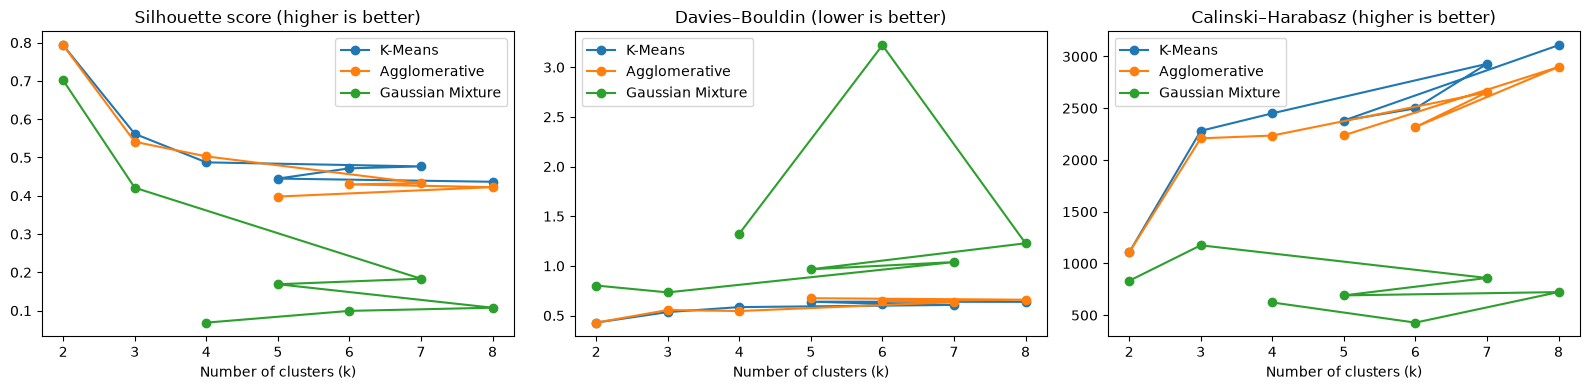

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for method_name in cluster_comparison["method"].unique():
    subset = cluster_comparison[cluster_comparison["method"] == method_name]
    axes[0].plot(subset["k"], subset["silhouette_score"], marker="o", label=method_name)
    axes[1].plot(subset["k"], subset["davies_bouldin_score"], marker="o", label=method_name)
    axes[2].plot(subset["k"], subset["calinski_harabasz_score"], marker="o", label=method_name)

axes[0].set_title("Silhouette score (higher is better)")
axes[1].set_title("Davies–Bouldin (lower is better)")
axes[2].set_title("Calinski–Harabasz (higher is better)")

for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
    ax.legend()

plt.tight_layout()
plt.show()

### Outcome and conclusion

The charts show how each clustering method behaves as the number of groups changes. If one method performs well across more than one measure, it may be a stronger candidate.

Sometimes the measures disagree. In that case, we should not choose a model from one score alone. We should consider the cluster sizes, how easy the groups are to explain, and whether the groups reveal useful patterns in the product catalogue.

## 14. Select the best clustering candidate

In [14]:
best_cluster_row = cluster_comparison.iloc[0]
best_cluster_method = str(best_cluster_row["method"])
best_cluster_k = int(best_cluster_row["k"])
best_cluster_result = cluster_fitted[(best_cluster_method, best_cluster_k)]

selected_cluster_model = best_cluster_result["model"]
selected_cluster_labels = best_cluster_result["all_labels"]

clustered_multi = analysis.copy()
clustered_multi["cluster"] = selected_cluster_labels

print("Selected method:", best_cluster_method)
print("Selected number of clusters:", best_cluster_k)
print("Silhouette score:", round(float(best_cluster_row["silhouette_score"]), 4))
print("Davies-Bouldin score:", round(float(best_cluster_row["davies_bouldin_score"]), 4))
print("Calinski-Harabasz score:", round(float(best_cluster_row["calinski_harabasz_score"]), 2))

display(
    clustered_multi["cluster"]
    .value_counts()
    .sort_index()
    .rename("records")
    .to_frame()
)

Selected method: K-Means
Selected number of clusters: 2
Silhouette score: 0.7933
Davies-Bouldin score: 0.4288
Calinski-Harabasz score: 1106.53


,records
cluster,
0,1723
1,54


### Outcome and conclusion

The candidate at the top of the comparison table is selected using the highest silhouette score, with Davies–Bouldin score as a secondary check. This is a data-driven starting choice, not proof that the method is best for every future dataset.

We also inspect the number of records in each selected cluster. Very small groups may represent specialist products or unusual records, so their composition needs careful review.

## 15. Inspect selected clusters and material-family composition

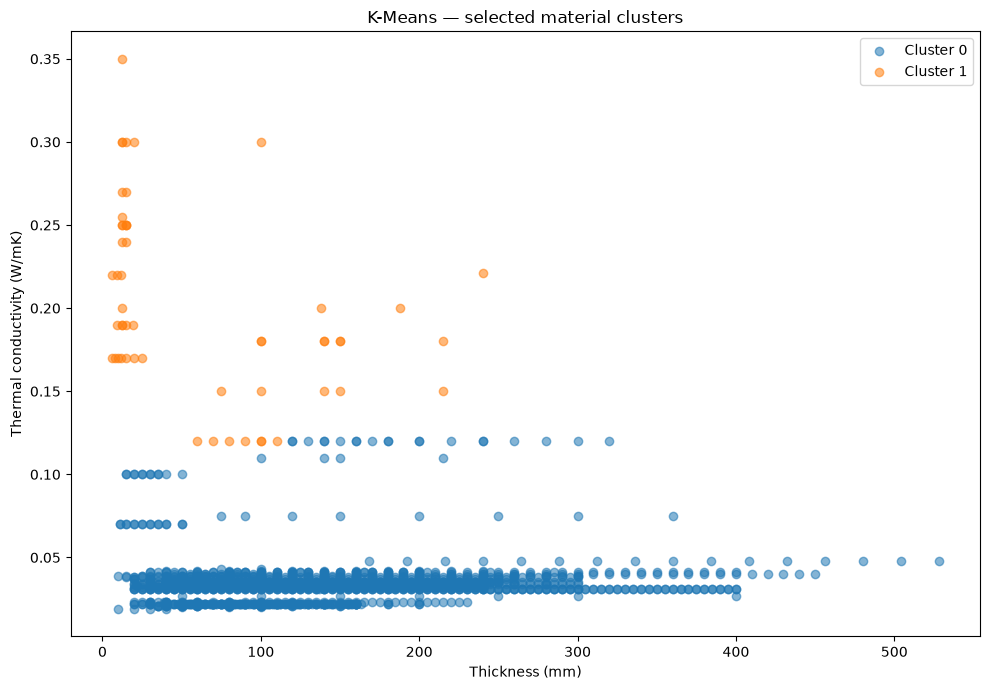

,records,average_thickness_mm,median_thickness_mm,average_thermal_conductivity_W_mK,median_thermal_conductivity_W_mK
cluster,,,,,
0,1723,139.540,123.0,0.034,0.033
1,54,62.315,17.0,0.201,0.190


material_family,AAC,CLT,EPS,Gypsum board,PF,PIR,PIR_sandwich_panel,PUR,PUR_sandwich_panel,XPS,...,glass_wool,glass_wool_loosefill,gypsum_board,gypsum_specialist_board,hemp_lime,polyester_wool,recycled_cotton,stone_wool,wood_fibre,wood_wool
cluster,,,,,,,,,,,,,,,,,,,,,
0,4,20,366,0,24,187,63,25,14,167,...,415,12,0,0,8,28,16,151,34,28
1,12,7,0,1,0,0,0,0,0,0,...,0,0,13,6,0,0,0,0,0,0


In [15]:
plt.figure(figsize=(10, 7))
for cluster_id in sorted(clustered_multi["cluster"].unique()):
    subset = clustered_multi[clustered_multi["cluster"] == cluster_id]
    plt.scatter(
        subset["thickness_mm"],
        subset["thermal_conductivity_W_mK"],
        alpha=0.55,
        label=f"Cluster {cluster_id}"
    )
plt.xlabel("Thickness (mm)")
plt.ylabel("Thermal conductivity (W/mK)")
plt.title(f"{best_cluster_method} — selected material clusters")
plt.legend()
plt.tight_layout()
plt.show()

selected_profile = (
    clustered_multi.groupby("cluster")
    .agg(
        records=("record_id", "count"),
        average_thickness_mm=("thickness_mm", "mean"),
        median_thickness_mm=("thickness_mm", "median"),
        average_thermal_conductivity_W_mK=("thermal_conductivity_W_mK", "mean"),
        median_thermal_conductivity_W_mK=("thermal_conductivity_W_mK", "median")
    )
    .round(3)
)
display(selected_profile)

selected_family_counts = pd.crosstab(
    clustered_multi["cluster"],
    clustered_multi["material_family"]
)
display(selected_family_counts)

### Outcome and conclusion

The scatter plot and profile table explain what the selected method has grouped together. The family table shows whether a cluster is dominated by one material family or combines different families with similar selected properties.

A cluster is only a similarity group based on thickness and thermal conductivity. It does not establish that products are interchangeable or suitable for the same application.

## 16. Save multi-method clustering comparison

In [16]:
multi_comparison_path = REPORT_DIR / "material_clustering_model_comparison_v1.csv"
multi_results_path = REPORT_DIR / "material_clustering_multi_method_results_v1.csv"
multi_profile_path = REPORT_DIR / "material_clustering_multi_method_profile_v1.csv"
multi_model_path = MODEL_DIR / "best_material_clustering_model_v1.joblib"
multi_summary_path = REPORT_DIR / "material_clustering_multi_method_summary_v1.json"

cluster_comparison.to_csv(multi_comparison_path, index=False)
clustered_multi.to_csv(multi_results_path, index=False)
selected_profile.to_csv(multi_profile_path)

artifact = {
    "method": best_cluster_method,
    "k": best_cluster_k,
    "model": selected_cluster_model,
    "scaler": scaler,
    "agglomerative_centroids": best_cluster_result["centroids"]
}
joblib.dump(artifact, multi_model_path)

multi_summary = {
    "experiment": "Multi-method material clustering",
    "dataset_version": "v1.5.0",
    "features": feature_columns,
    "eligible_records": int(len(analysis)),
    "training_records": int(train_mask.sum()),
    "selected_method": best_cluster_method,
    "selected_k": best_cluster_k,
    "selection_rule": "Highest training silhouette score; Davies-Bouldin used as secondary check",
    "selected_metrics": {
        "silhouette_score": float(best_cluster_row["silhouette_score"]),
        "davies_bouldin_score": float(best_cluster_row["davies_bouldin_score"]),
        "calinski_harabasz_score": float(best_cluster_row["calinski_harabasz_score"])
    },
    "warning": "Clusters represent similarity in selected features, not product approval or engineering classification."
}
multi_summary_path.write_text(json.dumps(multi_summary, indent=2), encoding="utf-8")

print("Saved model comparison:", multi_comparison_path)
print("Saved selected model and scaler:", multi_model_path)
print("Saved cluster assignments:", multi_results_path)
print("Saved cluster profile:", multi_profile_path)
print("Saved summary:", multi_summary_path)

Saved model comparison: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_clustering_model_comparison_v1.csv
Saved selected model and scaler: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\03_Models\material_clustering\best_material_clustering_model_v1.joblib
Saved cluster assignments: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_clustering_multi_method_results_v1.csv
Saved cluster profile: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI\06_AI_Performance_Engine\02_ML_Engine\04_Evaluation\reports\material_clustering_multi_method_profile_v1.csv
Saved summary: D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\03-Research Studio\SpecSynth_AI

# Final conclusion — Material Clustering

The initial experiment used K-Means. This extended experiment compares K-Means, Gaussian Mixture Model and Agglomerative Clustering across cluster counts from 2 to 8.

The methods are compared using three measures:
- Silhouette score: higher is generally better.
- Davies–Bouldin score: lower is generally better.
- Calinski–Harabasz score: higher is generally better.

The candidate with the highest training silhouette score is selected, with Davies–Bouldin used as a secondary check. The selected clusters are then inspected using their property profiles and material-family composition.

These scores describe mathematical separation and compactness. They do not prove that the groups are useful engineering categories. Only thickness and thermal conductivity are used, and the dataset contains many more insulation records than some other product families.

**Final takeaway:** Comparing several clustering algorithms gives us a stronger basis for selecting a grouping method than relying on K-Means alone. The selected clusters remain exploratory similarity groups—not compliance decisions, material approvals or replacement recommendations.

After running this updated notebook, review the comparison metrics and the selected cluster profiles. We should decide whether the groups are useful for SpecSynth AI only after considering both the numerical scores and their construction-material meaning.